In [1]:
# Per leggere i file
import gzip
import pickle
import math

import numpy as np
from sktime.clustering.k_means import TimeSeriesKMeans
from sklearn.cluster import AgglomerativeClustering
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
import pandas as pd
from tqdm.notebook import tqdm
from sktime.transformations.panel.catch22 import Catch22
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN
from sklearn.cluster import OPTICS

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer


# Dim reduction
import pacmap
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# per feature importance
from sklearn.ensemble import RandomForestClassifier

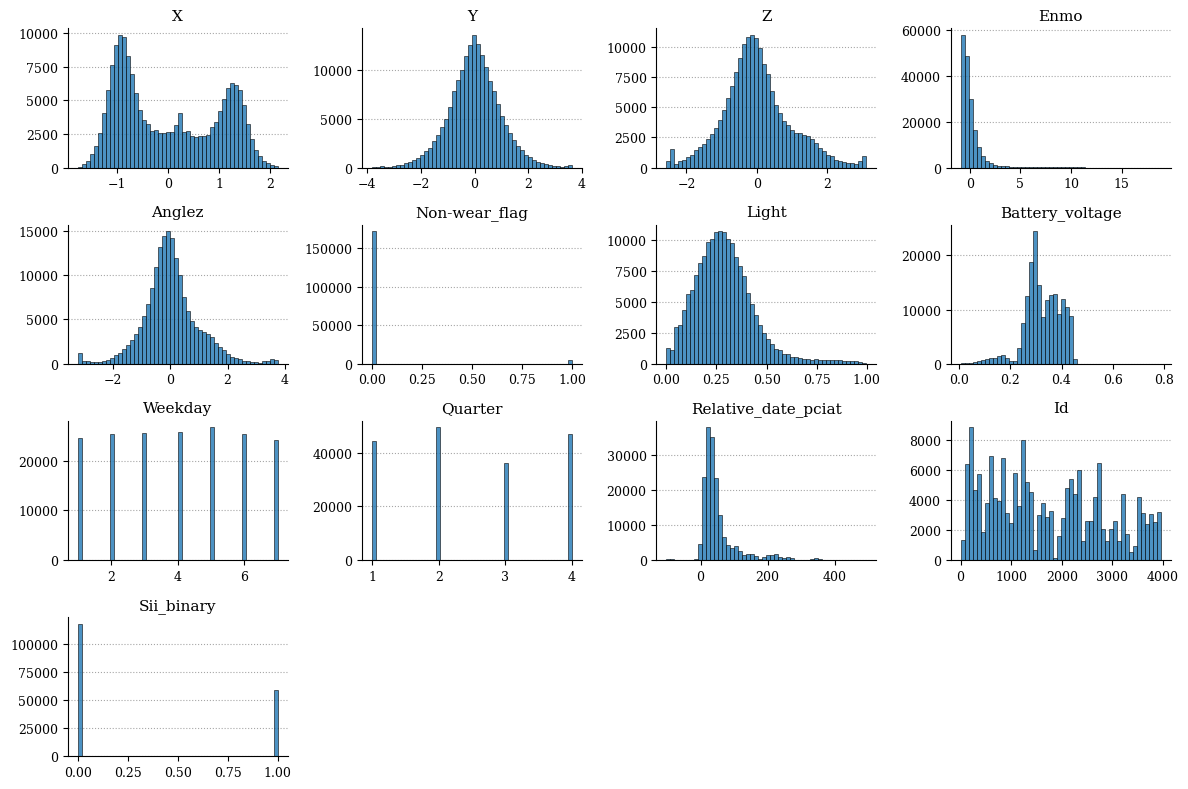

In [ ]:
import gzip
import pickle
import pandas as pd
import matplotlib.pyplot as plt

# Impostazioni globali per layout accademico
plt.rcParams.update({
    'font.family': 'serif',
    'axes.labelsize': 11,
    'axes.titlesize': 11,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'axes.spines.top': False,
    'axes.spines.right': False
})

# Caricamento dati
with gzip.open("ts_datasetwise_transformed_paa.pkl.gz", "rb") as f:
    ts = pickle.load(f)

ts_globale = pd.concat(ts, ignore_index=True)

# Optional: sampling to speed up plotting for massive datasets.
# Keep frac=1.0 to analyze 100% of the data.
df_plot = ts_globale.sample(frac=1.0, random_state=222)

# ==========================================
# Histogram Visualization
# ==========================================
# Generazione degli istogrammi tramite pandas
axes = df_plot.hist(
    bins=50,
    figsize=(12, 8),
    edgecolor='black',
    linewidth=0.5,
    grid=False,
    alpha=0.8,
    color='#1f77b4'
)

# Iterazione sui singoli subplot per applicare formattazioni di dettaglio
for ax in axes.flatten():
    if ax.has_data():  # Evita di formattare grafici vuoti nella griglia
        # Griglia orizzontale discreta per facilitare la lettura dei valori
        ax.yaxis.grid(True, linestyle=':', alpha=0.7, color='gray')
        ax.set_axisbelow(True)

        # Capitalizzazione del titolo della variabile e rimozione di eventuali formattazioni predefinite
        current_title = ax.get_title()
        ax.set_title(current_title.capitalize())


plt.tight_layout()
plt.show()

## Caricamento Dati
---

In [2]:
with gzip.open("ts_datasetwise_transformed_paa.pkl.gz", "rb") as f:
    ts = pickle.load(f)


# id non serve per il clustering, anzi può essere dannoso
for df in ts:
    if 'id' in df.columns:
        df.drop(columns=['id'], inplace=True)  # inutile
    if 'non-wear_flag' in df.columns:
        # inutile perchè quasi tutta = 0
        df.drop(columns=['non-wear_flag'], inplace=True)
    if 'battery_voltage' in df.columns:
        # inutile perchè quasi tutta = 0
        df.drop(columns=['battery_voltage'], inplace=True)
'''    if 'X' in df.columns:
        df.drop(columns=['X'], inplace=True)  # per multicollinearità
    if 'Y' in df.columns:
        df.drop(columns=['Y'], inplace=True)  # per multicollinearità
    if 'Z' in df.columns:
        df.drop(columns=['Z'], inplace=True)  # per multicollinearità'''

"    if 'X' in df.columns:\n        df.drop(columns=['X'], inplace=True)  # per multicollinearità\n    if 'Y' in df.columns:\n        df.drop(columns=['Y'], inplace=True)  # per multicollinearità\n    if 'Z' in df.columns:\n        df.drop(columns=['Z'], inplace=True)  # per multicollinearità"

In [ ]:
oppa = ts[0]

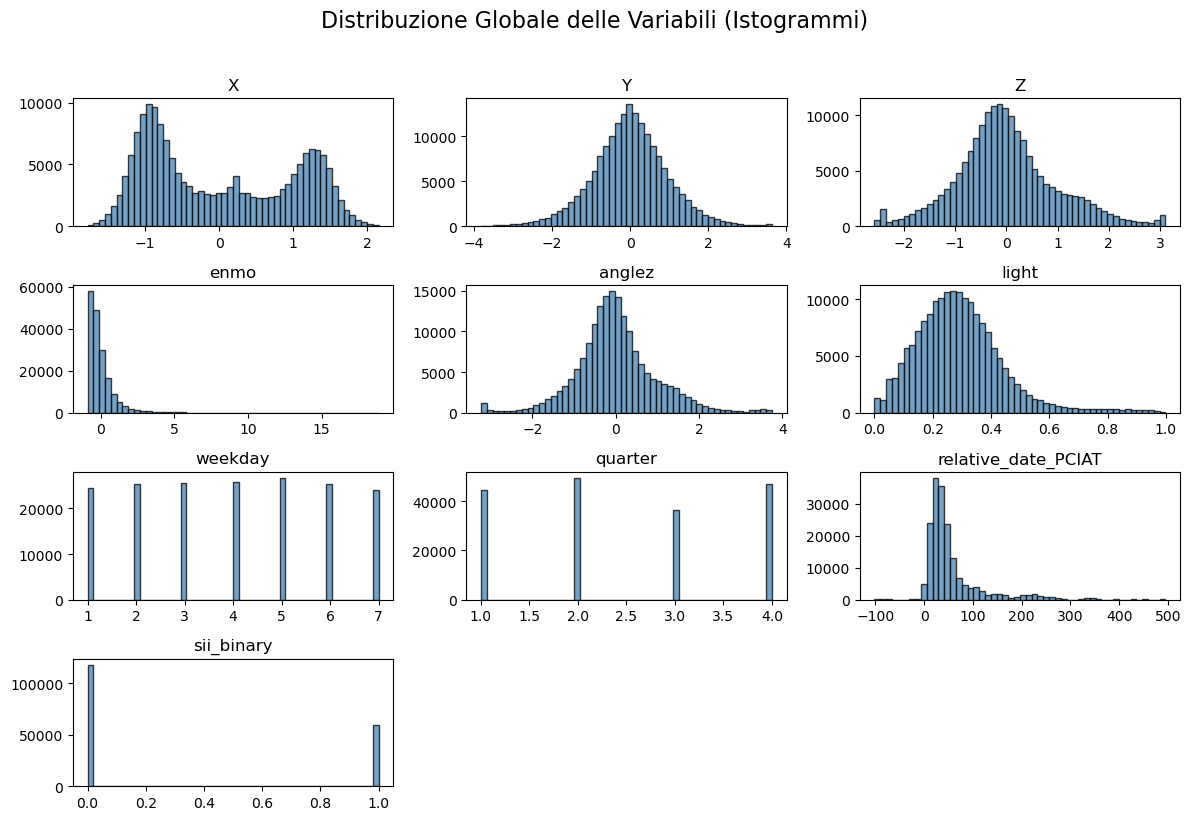

In [3]:
ts_globale = pd.concat(ts, ignore_index=True)

# Opzionale: campionamento per velocizzare la generazione grafica in caso di dataset massivi.
# Se si desidera analizzare il 100% dei dati, lasciare frac=1.0.
df_plot = ts_globale.sample(frac=1.0, random_state=222)

# ==========================================
# 3. Visualizzazione tramite Istogrammi
# ==========================================
# Viene creata una griglia automatica in base al numero di colonne
df_plot.hist(bins=50, figsize=(12, 8), edgecolor='black',
             grid=False, alpha=0.75, color='steelblue')
plt.suptitle("Distribuzione Globale delle Variabili (Istogrammi)",
             y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

## Approximate Clustering
---
Ho provato a fare whole clustering, ma era computazinalmente troppo pesante

In [4]:
# Gestione dati per clustering più memoria sii

sii_labels = []
weekday_labels = []
quarter_labels = []
relative_date_labels = []

X_clustering_list = []
X_flattened_list = []

for df in ts:
    # Si estraggono i valori (costanti per l'intera serie temporale)
    sii_labels.append(df['sii_binary'].iloc[0])
    weekday_labels.append(df['weekday'].iloc[0])
    quarter_labels.append(df['quarter'].iloc[0])
    relative_date_labels.append(df['relative_date_PCIAT'].iloc[0])

    # Rimozione delle colonne prima di passare i dati agli algoritmi
    colonne_da_rimuovere = ['sii_binary',
                            'weekday', 'quarter', 'relative_date_PCIAT']
    df_clustering = df.drop(columns=colonne_da_rimuovere)

    X_clustering_list.append(df_clustering)

    # Preparazione per il clustering gerarchico
    X_flattened_list.append(df_clustering.values.flatten())

# Conversione in array NumPy
sii_labels = np.array(sii_labels)
weekday_labels = np.array(weekday_labels)
quarter_labels = np.array(quarter_labels)
relative_date_labels = np.array(relative_date_labels)

X_flattened = np.array(X_flattened_list)

# Preparazione del formato 3D per sktime (n_istanze, n_variabili, n_timepoints)
X_array = np.array(X_clustering_list)
X_sktime = np.transpose(X_array, (0, 2, 1))

In [5]:
# Clustering

# K-Means Euclideo
kmeans_euclidean = TimeSeriesKMeans(
    n_clusters=3,
    metric="euclidean",
    init_algorithm="kmeans++",
    n_init=10,
    random_state=222
)
labels_kmeans_euclidean = kmeans_euclidean.fit_predict(X_sktime)

# K-Means DTW
kmeans_dtw = TimeSeriesKMeans(
    n_clusters=3,
    metric="dtw",
    init_algorithm="kmeans++",
    n_init=10,
    random_state=222,
    distance_params={"window": 0.1}
)
labels_kmeans_dtw = kmeans_dtw.fit_predict(X_sktime)

# Clustering Gerarchico (Agglomerativo)

k_ger = 3
hierarchical_euclidean = AgglomerativeClustering(
    n_clusters=k_ger,
    metric='euclidean',
    linkage='ward'
)
labels_ger_euclidean = hierarchical_euclidean.fit_predict(X_flattened)

'''hierarchical_dtw = AgglomerativeClustering(
    n_clusters=k_ger,
    metric='dtw',
    linkage='ward'
)
labels_ger_dtw = hierarchical_dtw.fit_predict(X_flattened)'''


print("Numerosità K-Means Euclideo:", np.bincount(labels_kmeans_euclidean))
print("Numerosità K-Means DTW:", np.bincount(labels_kmeans_dtw))
print("Numerosità Gerarchico Euclideo:", np.bincount(labels_ger_euclidean))
# print("Numerosità Gerarchico DTW:", np.bincount(labels_ger_dtw))

Numerosità K-Means Euclideo: [1411  744 2282]
Numerosità K-Means DTW: [ 744 1408 2285]
Numerosità Gerarchico Euclideo: [2427 1573  437]


## Visualizzazione
---

In [6]:
# Per Grafici
dict_labels = {
    "labels_kmeans_euclidean": labels_kmeans_euclidean,
    "labels_kmeans_dtw": labels_kmeans_dtw,
    "labels_ger_euclidean": labels_ger_euclidean
}

### Feature Importance

In [ ]:
'''colonne_reali = X_clustering_list[0].columns.tolist()
n_timepoints = len(X_clustering_list[0])
feature_names = []
for t in range(n_timepoints):
    for col in colonne_reali:
        feature_names.append(f"{col}_t{t}")

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
fig.suptitle(
    "Importanza Globale delle Variabili nei 3 Modelli di Clustering", fontsize=16)

for ax, (nome_modello, labels) in zip(axes, dict_labels.items()):

    clf = RandomForestClassifier(random_state=222, n_estimators=100)
    clf.fit(X_flattened, labels)

    importances = clf.feature_importances_

    df_importance = pd.DataFrame({
        'Feature': feature_names,
        'Importance': importances
    })

    df_importance['Variable_Group'] = df_importance['Feature'].apply(
        lambda x: x.split('_t')[0])
    df_group_importance = df_importance.groupby(
        'Variable_Group')['Importance'].sum().reset_index()
    df_group_importance = df_group_importance.sort_values(
        by='Importance', ascending=False)

    print(f"\nImportanza globale - {nome_modello}:")
    print(df_group_importance.to_string(index=False))

    # Visualizzazione grafica nel subplot corrispondente
    ax.bar(
        df_group_importance['Variable_Group'],
        df_group_importance['Importance'],
        color='teal',
        edgecolor='black'
    )

    # Formattazione del singolo grafico
    ax.set_title(nome_modello)
    ax.set_xlabel('Variabile Originale')
    ax.tick_params(axis='x', rotation=45)

    # Inserimento della label y solo sul primo grafico a sinistra
    if ax == axes[0]:
        ax.set_ylabel('Importanza Totale Cumulata')

# Ottimizzazione degli spazi
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()'''

### 2D Visualization

In [ ]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import pacmap
import matplotlib.pyplot as plt

# ==========================================
# 1. Riduzione della Dimensionalità
# ==========================================

# PCA
pca = PCA(n_components=2, random_state=222)
X_pca = pca.fit_transform(X_flattened)

# t-SNE
tsne = TSNE(n_components=2, random_state=222)
X_tsne = tsne.fit_transform(X_flattened)

# PacMAP
pm = pacmap.PaCMAP(n_components=2, random_state=222)
X_pacmap = pm.fit_transform(X_flattened, init="pca")

# ==========================================
# 2. Visualizzazione Unificata a Righe Separate
# ==========================================

tecniche_riduzione = [
    ('PCA', X_pca),
    ('t-SNE', X_tsne),
    ('PacMAP', X_pacmap)
]

nomi_righe_formattati = {
    'labels_kmeans_euclidean': 'K-Means\nEuclidean',
    'labels_kmeans_dtw': 'K-Means\nDTW',
    'labels_ger_euclidean': 'Hierarchical\nEuclidean'
}

n_rows = len(dict_labels)
n_cols = len(tecniche_riduzione)

# Creazione della figura principale
fig = plt.figure(figsize=(12, 3.5 * n_rows), constrained_layout=True)

# Divisione della figura in 3 sotto-figure distinte orizzontalmente (una per ogni algoritmo di clustering)
subfigs = fig.subfigures(n_rows, 1, hspace=0.05)

scatter_ref = None

for row_idx, ((nome_clustering, labels_cluster), subfig) in enumerate(zip(dict_labels.items(), subfigs)):
    nome_visualizzato = nomi_righe_formattati.get(
        nome_clustering, nome_clustering)

    # Creazione della griglia interna alla singola sotto-figura (1 riga, 3 colonne)
    axs = subfig.subplots(1, n_cols, squeeze=False)

    for col_idx, (nome_riduzione, X_vis) in enumerate(tecniche_riduzione):
        ax = axs[0, col_idx]

        # Generazione scatter plot
        scatter = ax.scatter(X_vis[:, 0], X_vis[:, 1], c=labels_cluster,
                             cmap='tab10', alpha=0.7, edgecolors='w', linewidth=0.5)

        if scatter_ref is None:
            scatter_ref = scatter

        # Inserimento titoli colonne (tecniche di riduzione) solo sulla prima sotto-figura (prima riga globale)
        if row_idx == 0:
            ax.set_title(nome_riduzione, fontsize=13, fontweight='bold')

        # Inserimento titoli righe formattati esclusivamente sulla prima colonna di ogni sotto-figura
        if col_idx == 0:
            ax.set_ylabel(nome_visualizzato, fontsize=12, fontweight='bold',
                          labelpad=30, rotation=0, ha='right', va='center')

# Aggiunta di una singola legenda globale ancorata alla figura principale
legend_elements = scatter_ref.legend_elements()[0]
labels = [f"Cluster {i}" for i in range(len(legend_elements))]
fig.legend(legend_elements, labels, title="Cluster ID",
           bbox_to_anchor=(1.02, 0.5), loc='center left', frameon=False, fontsize=11)

plt.show()

In [ ]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import pacmap
import matplotlib.pyplot as plt

# ==========================================
# 1. Riduzione della Dimensionalità
# ==========================================

# PCA
pca = PCA(n_components=2, random_state=222)
X_pca = pca.fit_transform(X_flattened)

# t-SNE
tsne = TSNE(n_components=2, random_state=222)
X_tsne = tsne.fit_transform(X_flattened)

# PacMAP
pm = pacmap.PaCMAP(n_components=2, random_state=222)
X_pacmap = pm.fit_transform(X_flattened, init="pca")

# ==========================================
# 2. Visualizzazione in Figure Separate
# ==========================================

tecniche_riduzione = [
    ('PCA', X_pca),
    ('t-SNE', X_tsne),
    ('PacMAP', X_pacmap)
]

nomi_righe_formattati = {
    'labels_kmeans_euclidean': 'K-Means\nEuclidean',
    'labels_kmeans_dtw': 'K-Means\nDTW',
    'labels_ger_euclidean': 'Hierarchical\nEuclidean'
}

n_cols = len(tecniche_riduzione)

for nome_clustering, labels_cluster in dict_labels.items():
    nome_visualizzato = nomi_righe_formattati.get(
        nome_clustering, nome_clustering)

    # Creazione di una figura completamente indipendente per l'algoritmo corrente
    fig, axs = plt.subplots(1, n_cols, figsize=(
        12, 3.5), constrained_layout=True)

    scatter_ref = None

    for col_idx, (nome_riduzione, X_vis) in enumerate(tecniche_riduzione):
        ax = axs[col_idx]

        # Generazione scatter plot
        scatter = ax.scatter(X_vis[:, 0], X_vis[:, 1], c=labels_cluster,
                             cmap='tab10', alpha=0.7, edgecolors='w', linewidth=0.5)

        if scatter_ref is None:
            scatter_ref = scatter

        # Titolo colonna (tecnica di riduzione)
        ax.set_title(nome_riduzione, fontsize=13, fontweight='bold')

        # Titolo riga (metodo di clustering) solo sul primo grafico a sinistra
        if col_idx == 0:
            ax.set_ylabel(nome_visualizzato, fontsize=12, fontweight='bold',
                          labelpad=30, rotation=0, ha='right', va='center')

    # Aggiunta della legenda specifica per questa figura
    legend_elements = scatter_ref.legend_elements()[0]
    labels = [f"Cluster {i}" for i in range(len(legend_elements))]
    fig.legend(legend_elements, labels, title="Cluster ID",
               bbox_to_anchor=(1.02, 0.5), loc='center left', frameon=False, fontsize=11)

    # Mostra la figura corrente prima di passare alla successiva
    plt.show()

### Visualizzazione Centroidi

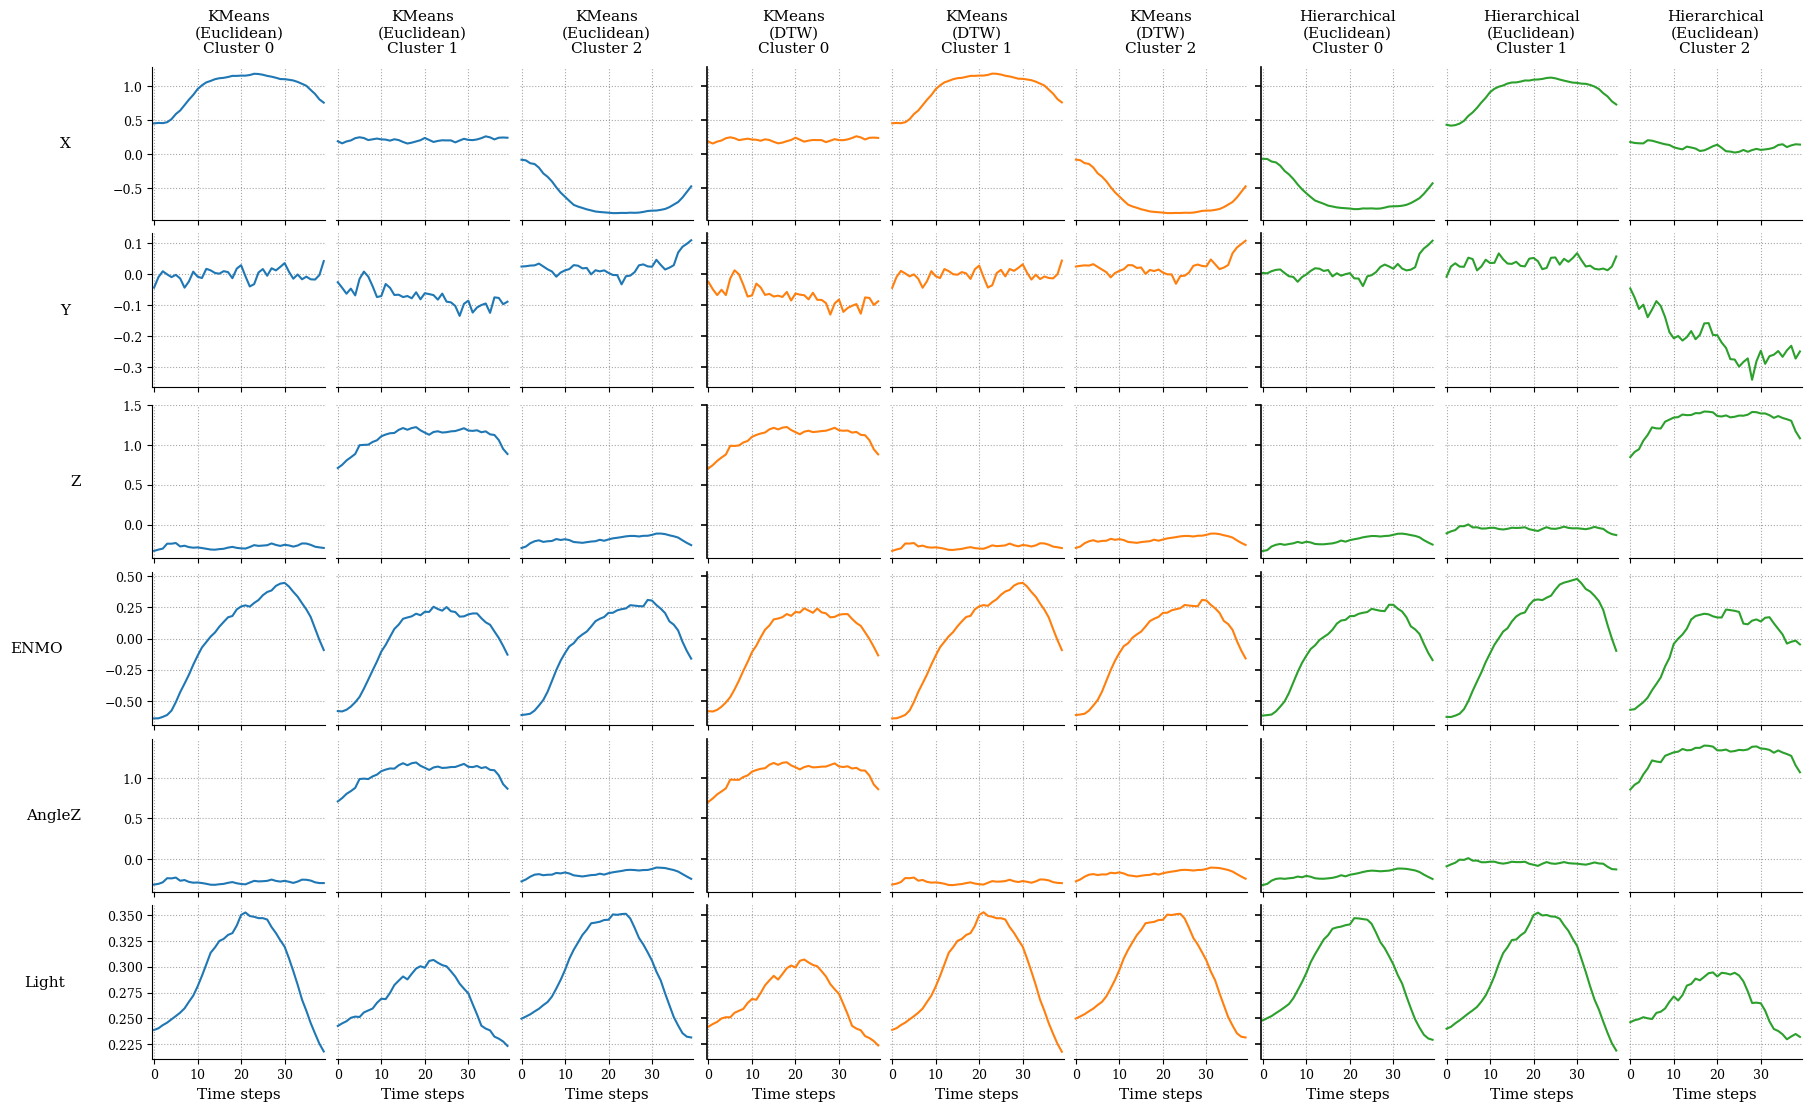

In [ ]:
plt.rcParams.update({
    'font.family': 'serif',
    'axes.labelsize': 11,
    'axes.titlesize': 11,
    'legend.fontsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9
})

centroidi_euclidean = kmeans_euclidean.cluster_centers_
centroidi_dtw = kmeans_dtw.cluster_centers_

centroidi_ger_list = []
for cluster_id in range(k_ger):
    serie_nel_cluster = X_sktime[labels_ger_euclidean == cluster_id]
    centroide = np.mean(serie_nel_cluster, axis=0)
    centroidi_ger_list.append(centroide)

centroidi_ger = np.array(centroidi_ger_list)

# Nomi formattati senza trattino per coerenza
dict_centroids = {
    "KMeans\n(Euclidean)": centroidi_euclidean,
    "KMeans\n(DTW)": centroidi_dtw,
    "Hierarchical\n(Euclidean)": centroidi_ger
}

# Definizione dei colori per ciascun algoritmo
colori_tecniche = {
    "KMeans\n(Euclidean)": "#1f77b4",
    "KMeans\n(DTW)": "#ff7f0e",
    "Hierarchical\n(Euclidean)": "#2ca02c"
}

# Nomi delle variabili capitalizzati correttamente per la visualizzazione
nomi_colonne = ["X", "Y", "Z", "ENMO", "AngleZ", "Light"]

# ==========================================
# 2. Visualizzazione Unificata
# ==========================================

num_algos = len(dict_centroids)
num_clusters = len(centroidi_euclidean)
num_vars = len(nomi_colonne)
total_cols = num_algos * num_clusters

# Creazione griglia
fig, axes = plt.subplots(
    nrows=num_vars,
    ncols=total_cols,
    figsize=(18, 11),
    sharex=True,
    sharey='row',
    constrained_layout=True
)

col_idx = 0
for nome_tecnica, centroidi in dict_centroids.items():
    colore_corrente = colori_tecniche[nome_tecnica]

    for c_idx, centroide in enumerate(centroidi):
        centroide_trasposto = centroide.T

        for v_idx, col_name in enumerate(nomi_colonne):
            ax = axes[v_idx, col_idx]

            ax.plot(centroide_trasposto[:, v_idx],
                    color=colore_corrente, linewidth=1.5)

            # Intestazioni delle colonne (solo sulla prima riga)
            if v_idx == 0:
                ax.set_title(f"{nome_tecnica}\nCluster {c_idx}", pad=10)

            # Etichette asse Y (solo sulla prima colonna assoluta)
            if col_idx == 0:
                ax.set_ylabel(col_name, rotation=0, labelpad=30,
                              ha='right', va='center')

            # Etichette asse X (solo sull'ultima riga)
            if v_idx == num_vars - 1:
                ax.set_xlabel("Time steps")

            # Pulizia estetica standard
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.grid(True, linestyle=':', alpha=0.7, color='gray')
            ax.margins(x=0.01)

            # Gestione della separazione visiva tra gli algoritmi e pulizia degli assi interni
            if col_idx > 0 and col_idx % num_clusters == 0:
                # Bordo sinistro marcato per il primo grafico di un nuovo algoritmo
                ax.spines['left'].set_linewidth(1.2)
                ax.spines['left'].set_color('black')
                ax.tick_params(axis='y', left=True, length=4, width=1.2)
            else:
                # Nasconde asse Y e ticks per i grafici interni allo stesso algoritmo
                if col_idx % num_clusters != 0:
                    ax.spines['left'].set_visible(False)
                    ax.tick_params(axis='y', left=False)

        col_idx += 1

plt.show()

### Istogrammi dei Clusters

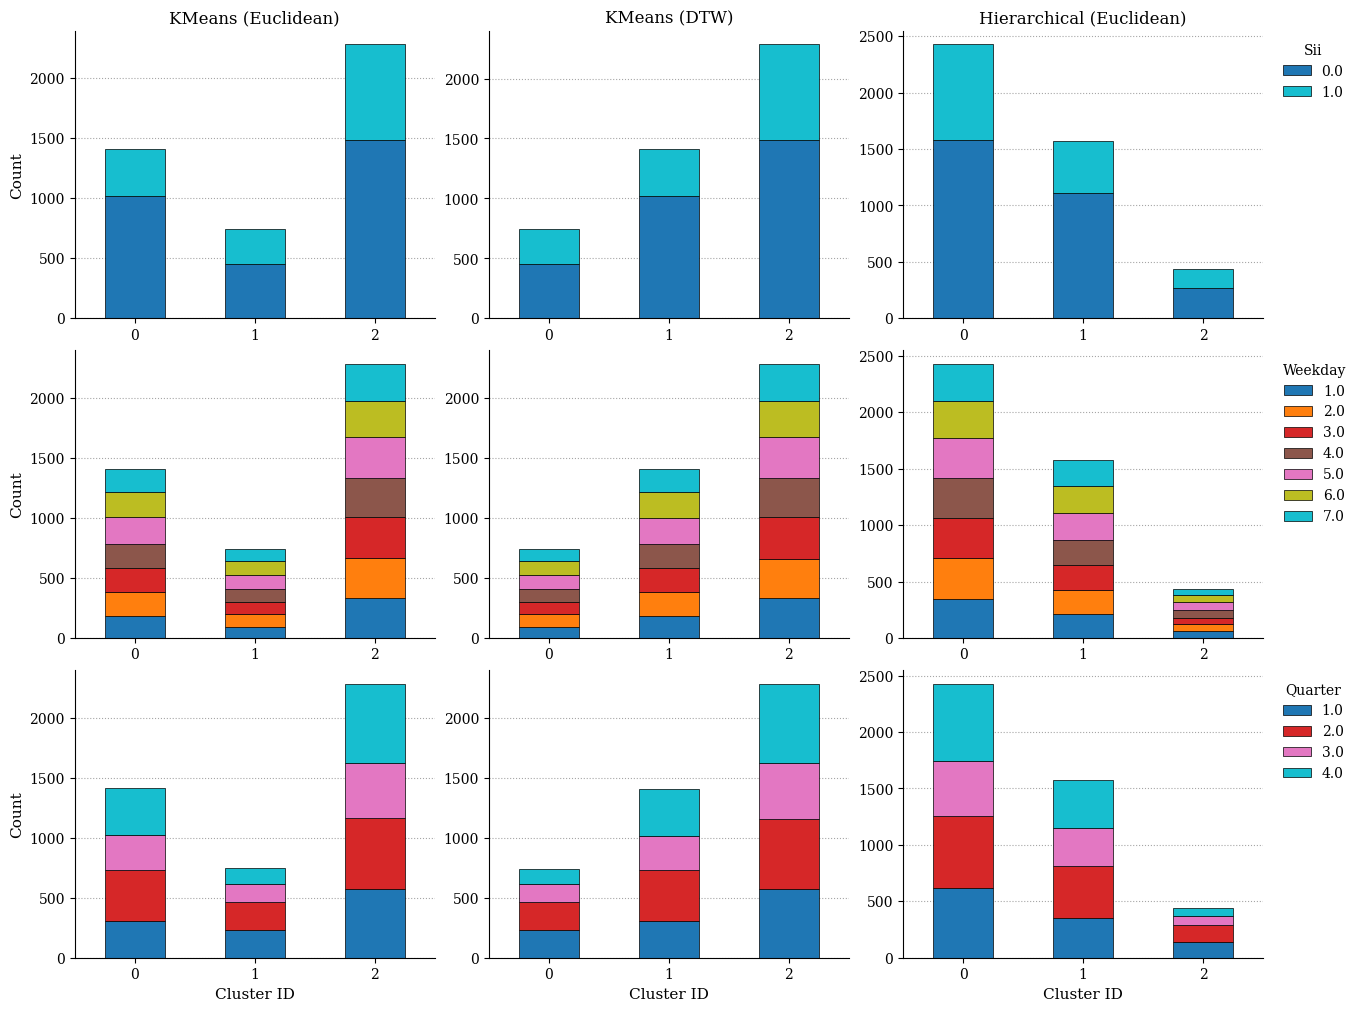

Mean 'relative_date_PCIAT' by Cluster and Algorithm:
------------------------------------------------------------
            KMeans (Euclidean)  KMeans (DTW)  Hierarchical (Euclidean)
Cluster ID                                                            
0                       52.625        73.515                    49.681
1                       73.378        52.675                    54.439
2                       49.303        49.232                    80.430
------------------------------------------------------------


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.family': 'serif',
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'legend.fontsize': 10,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10
})

# Funzione per formattare i nomi delle tecniche


def format_technique_name(raw_name):
    clean = raw_name.replace('labels-', '').replace('labels_', '')
    mapping = {
        'kmeans_euclidean': 'KMeans (Euclidean)',
        'kmeans_dtw': 'KMeans (DTW)',
        'ger_euclidean': 'Hierarchical (Euclidean)'
    }
    return mapping.get(clean, clean.replace('_', ' ').title())


n_cols = len(dict_labels)

# Definition of variables to plot
# Palette uniformata a 'tab10' per tutte le variabili
plot_variables = [
    ('Sii', sii_labels, 'tab10'),
    ('Weekday', weekday_labels, 'tab10'),
    ('Quarter', quarter_labels, 'tab10')
]

fig, axes = plt.subplots(3, n_cols, figsize=(
    4.5 * n_cols, 10), squeeze=False, constrained_layout=True)
# fig.suptitle("Variable Distribution by Cluster", fontsize=14, y=1.05)

for row_idx, (var_name, var_labels, color_config) in enumerate(plot_variables):
    for col_idx, (nome_tecnica, labels_cluster) in enumerate(dict_labels.items()):
        ax = axes[row_idx, col_idx]

        df_plot = pd.DataFrame(
            {'Cluster': labels_cluster, var_name: var_labels})
        crosstab = pd.crosstab(df_plot['Cluster'], df_plot[var_name])

        # Plotting diretto tramite colormap
        crosstab.plot(kind='bar', stacked=True, ax=ax, cmap=color_config,
                      legend=False, edgecolor='black', linewidth=0.5)

        # Formattazione degli assi e della griglia
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.yaxis.grid(True, linestyle=':', alpha=0.7, color='gray')
        ax.set_axisbelow(True)

        if row_idx == 0:
            technique_name = format_technique_name(nome_tecnica)
            ax.set_title(technique_name)

        if col_idx == 0:
            ax.set_ylabel("Count")
        else:
            ax.set_ylabel("")

        if row_idx == 2:
            ax.set_xlabel("Cluster ID")
        else:
            ax.set_xlabel("")

        ax.tick_params(axis='x', rotation=0)

    # Legenda singola per riga
    axes[row_idx, -1].legend(title=var_name, bbox_to_anchor=(1.02,
                             1), loc='upper left', frameon=False)

plt.show()

# Calcolo medie
dict_means = {}

for nome_tecnica, labels_cluster in dict_labels.items():
    df_temp = pd.DataFrame({
        'Cluster': labels_cluster,
        'relative_date_PCIAT': relative_date_labels
    })

    mean_per_cluster = df_temp.groupby(
        'Cluster')['relative_date_PCIAT'].mean().round(3)
    technique_name = format_technique_name(nome_tecnica)
    dict_means[technique_name] = mean_per_cluster

df_means = pd.DataFrame(dict_means)
df_means.index.name = 'Cluster ID'

print("Mean 'relative_date_PCIAT' by Cluster and Algorithm:")
print("-" * 60)
print(df_means.to_string())
print("-" * 60)

## Validazione
---

In [ ]:
'''# ==========================================
# 1. Validazione per K-Means (Euclideo)
# ==========================================
k_range = range(2, 20)
inertia_values = []
silhouette_scores = []

for k_val in tqdm(k_range, desc="Validazione Euclidea"):
    kmeans_eval = TimeSeriesKMeans(
        n_clusters=k_val,
        metric="euclidean",
        random_state=222,
        init_algorithm="kmeans++",
        n_init=2
    )
    labels_eval = kmeans_eval.fit_predict(X_sktime)
    inertia_values.append(kmeans_eval.inertia_)
    score = silhouette_score(X_flattened, labels_eval, metric='euclidean')
    silhouette_scores.append(score)

# Visualizzazione Metodo del Gomito e Silhouette
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(k_range, inertia_values, marker='o', color='blue')
ax1.set_title('Metodo del Gomito (Elbow Method)')
ax1.set_xlabel('Numero di Cluster (k)')
ax1.set_ylabel('Inerzia')
ax1.grid(True, linestyle='--', alpha=0.7)

ax2.plot(k_range, silhouette_scores, marker='o', color='orange')
ax2.set_title('Indice di Silhouette')
ax2.set_xlabel('Numero di Cluster (k)')
ax2.set_ylabel('Silhouette Score Medio')
ax2.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


# ==========================================
# 1.5 Validazione per K-Means (DTW)
# ==========================================
k_range_dtw = range(2, 10)
inertia_values_dtw = []
silhouette_scores_dtw = []

# Implementazione di tqdm per monitorare il ciclo
for k_val in tqdm(k_range_dtw, desc="Validazione DTW"):
    kmeans_eval = TimeSeriesKMeans(
        n_clusters=k_val,
        metric="dtw",
        random_state=222,
        init_algorithm="kmeans++",
        n_init=2,
        distance_params={"window": 0.1}
    )
    labels_eval = kmeans_eval.fit_predict(X_sktime)
    inertia_values_dtw.append(kmeans_eval.inertia_)
    score = silhouette_score(X_flattened, labels_eval, metric='euclidean')
    silhouette_scores_dtw.append(score)


# Visualizzazione Metodo del Gomito e Silhouette
# Visualizzazione Metodo del Gomito e Silhouette - DTW
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Sostituzione delle variabili con quelle del DTW
ax1.plot(k_range_dtw, inertia_values_dtw, marker='o', color='blue')
ax1.set_title('Metodo del Gomito (Elbow Method) - DTW')
ax1.set_xlabel('Numero di Cluster (k)')
ax1.set_ylabel('Inerzia')
ax1.grid(True, linestyle='--', alpha=0.7)

ax2.plot(k_range_dtw, silhouette_scores_dtw, marker='o', color='orange')
ax2.set_title('Indice di Silhouette - DTW')
ax2.set_xlabel('Numero di Cluster (k)')
ax2.set_ylabel('Silhouette Score Medio')
ax2.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

plt.tight_layout()
plt.show()

# ==========================================
# 2. Validazione per Clustering Gerarchico
# ==========================================
# Il linkage 'ward' calcola le distanze in base alla varianza ed è coerente con l'implementazione
Z = linkage(X_flattened, method='ward')

plt.figure(figsize=(12, 7))
plt.title("Dendrogramma per la Scelta di K")
# Troncamento visivo per evitare un albero illeggibile in presenza di molti campioni
dendrogram(Z, truncate_mode='lastp', p=40)
plt.xlabel("Dimensione dei cluster / Indici dei campioni")
plt.ylabel("Distanza di Ward")
plt.show()'''

In [ ]:
'''import numpy as np
import itertools
from sklearn.metrics import silhouette_score
from tqdm import tqdm
# Assumendo l'import di TimeSeriesKMeans da sktime

# 1. Definizione delle configurazioni di constraint per DTW
# A causa del bug di validazione interno di sktime sul parametro itakura_max_slope,
# lo spazio di ricerca viene limitato esclusivamente all'ottimizzazione del
# parametro 'window' (Sakoe-Chiba band).
dtw_configs = [
    {"window": 0.01},
    {"window": 0.05},
    {"window": 0.10},
    {"window": 0.15},
    {"window": 0.20}
]

# Definizione dello spazio di ricerca
param_grid = {
    'n_clusters': [2, 3, 4, 5, 6],
    'dtw_params': dtw_configs
}

best_silhouette = -1
best_params = {}
best_labels = None
best_model = None

# Generazione di tutte le combinazioni per l'iteratore unico
combinazioni = list(itertools.product(
    param_grid['n_clusters'], param_grid['dtw_params']))

# Applicazione di tqdm sul ciclo unificato
for n_clusters, dist_params in tqdm(combinazioni, desc="Grid Search K-Means DTW"):
    kmeans_dtw = TimeSeriesKMeans(
        n_clusters=n_clusters,
        metric="dtw",
        init_algorithm="kmeans++",
        n_init=1,
        random_state=222,
        distance_params=dist_params
    )

    # Esecuzione del modello
    labels = kmeans_dtw.fit_predict(X_sktime)

    # Valutazione tramite Coefficiente di Silhouette
    if len(np.unique(labels)) > 1:
        score = silhouette_score(X_flattened, labels, metric='euclidean')

        if score > best_silhouette:
            best_silhouette = score
            best_params = {'n_clusters': n_clusters,
                           'distance_params': dist_params}
            best_labels = labels
            best_model = kmeans_dtw

print("Migliori parametri trovati:", best_params)
print("Miglior Silhouette Score:", best_silhouette)
print("Numerosità cluster ottimale:", np.bincount(best_labels))'''

## CATCH22
---

In [ ]:
with gzip.open("ts_datasetwise_normalized.pkl.gz", "rb") as f:
    ts_norm = pickle.load(f)

X_clustering_norm_list = []

# Colonne qualitative o non necessarie per il clustering/catch22 da rimuovere
colonne_da_rimuovere = ['sii_binary', 'weekday', 'quarter',
                        'relative_date_PCIAT', 'id', 'non-wear_flag', 'battery_voltage']

for df in ts_norm:
    # Rimozione delle colonne non rilevanti/qualitative
    # errors='ignore' evita blocchi se alcune colonne sono già state rimosse
    df_clustering = df.drop(columns=colonne_da_rimuovere, errors='ignore')
    X_clustering_norm_list.append(df_clustering)

# Conversione in array NumPy
X_array_norm = np.array(X_clustering_norm_list)

# Preparazione del formato 3D per sktime (n_istanze, n_variabili, n_timepoints)
# X_array_norm ha inizialmente forma (4500, 200, n_variabili_quantitative)
X_sktime_norm = np.transpose(X_array_norm, (0, 2, 1))

# Inizializzazione e applicazione dell'estrattore Catch22
catcher = Catch22()
X_catch22 = catcher.fit_transform(X_sktime_norm)

### RAW DATA
---

In [ ]:
iterative_imputer = IterativeImputer(max_iter=10, random_state=222)
X_catch22_imputed = iterative_imputer.fit_transform(X_catch22)


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_catch22_imputed)

#### Kmeans
----

In [ ]:
k_range = range(2, 15)
inertia_values = []
silhouette_scores = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=222, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    inertia_values.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(
        X_scaled, labels, metric='euclidean'))

# Generazione dei grafici
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Grafico Inerzia
ax1.plot(k_range, inertia_values, marker='o', color='blue')
ax1.set_title('K-Means: Metodo del Gomito')
ax1.set_xlabel('Numero di Cluster (k)')
ax1.set_ylabel('Inerzia')
ax1.grid(True, linestyle='--', alpha=0.7)

# Grafico Silhouette
ax2.plot(k_range, silhouette_scores, marker='o', color='orange')
ax2.set_title('K-Means: Indice di Silhouette')
ax2.set_xlabel('Numero di Cluster (k)')
ax2.set_ylabel('Silhouette Score')
ax2.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [ ]:
# Modello
kmeans_22 = KMeans(n_clusters=2, n_init=10, random_state=222)
labels_kmeans_22 = kmeans_22.fit_predict(X_scaled)

print("Numerosità:", np.bincount(labels_kmeans_22))

#### Gerarchico
----

In [ ]:
Z = linkage(X_scaled, method='ward')

plt.figure(figsize=(14, 7))
plt.title("Clustering Gerarchico: Dendrogramma")
# L'opzione truncate_mode='lastp' limita la visualizzazione agli ultimi p nodi uniti
dendrogram(Z, truncate_mode='lastp', p=50,
           leaf_rotation=90., leaf_font_size=10.)
plt.xlabel("Dimensione dei cluster / Indici dei campioni")
plt.ylabel("Distanza di Ward")
# Linea orizzontale di taglio (modificare y in base al grafico)
# plt.axhline(y=150, color='r', linestyle='--')
plt.show()

In [ ]:
ger_22 = AgglomerativeClustering(
    n_clusters=2,
    metric='euclidean',
    linkage='ward'
)
labels_ger_22 = ger_22.fit_predict(X_scaled)
print("Numerosità:", np.bincount(labels_ger_22))

#### DBSCAN
----

In [ ]:


# Definizione dello spazio di ricerca
# Nota: L'intervallo di eps dipende dalla dimensionalità e dalla densità dopo la standardizzazione
eps_values = np.linspace(0.5, 40.0, 80)
min_samples_values = [5, 10, 20, 30, 50]

best_score_dbscan = -1
best_params_dbscan = {}
best_labels_dbscan = None

for eps in eps_values:
    for min_samples in min_samples_values:
        dbscan = DBSCAN(eps=eps, min_samples=min_samples)
        labels = dbscan.fit_predict(X_scaled)

        # Calcolo del numero di cluster individuati (escludendo il rumore -1)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

        # Silhouette è calcolabile solo con almeno 2 cluster
        if n_clusters > 1:
            # Opzionale: calcolare la silhouette solo sui punti non-rumore per valutare i cluster
            mask = labels != -1
            if len(set(labels[mask])) > 1:
                score = silhouette_score(X_scaled[mask], labels[mask])

                if score > best_score_dbscan:
                    best_score_dbscan = score
                    best_params_dbscan = {
                        'eps': eps, 'min_samples': min_samples}
                    best_labels_dbscan = labels

print("--- DBSCAN Grid Search ---")
print("Migliori parametri:", best_params_dbscan)
print(f"Miglior Silhouette Score (escluso rumore): {best_score_dbscan:.4f}")
if best_labels_dbscan is not None:
    print("Numerosità cluster (incluso -1 per rumore):", np.bincount(
        best_labels_dbscan[best_labels_dbscan >= 0]), f"| Rumore: {np.sum(best_labels_dbscan == -1)}")

In [ ]:
dbscan22 = DBSCAN(eps=18.5, min_samples=10)
labels_dbscan22 = dbscan22.fit_predict(X_scaled)
print(pd.Series(labels_dbscan22).value_counts().sort_index())

#### OPTICS
----

<!-- ### DBSCAN
---- -->

In [ ]:

# Definizione dello spazio di ricerca
min_samples_optics = [5, 10, 20, 30, 50]
xi_values = np.linspace(0.01, 0.1, 5)

best_score_optics = -1
best_params_optics = {}
best_labels_optics = None

for min_samples in min_samples_optics:
    for xi in xi_values:
        # OPTICS può essere computazionalmente oneroso, n_jobs=-1 utilizza tutti i core
        optics = OPTICS(min_samples=min_samples, xi=xi, n_jobs=-1)
        labels = optics.fit_predict(X_scaled)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

        if n_clusters > 1:
            mask = labels != -1
            if len(set(labels[mask])) > 1:
                score = silhouette_score(X_scaled[mask], labels[mask])

                if score > best_score_optics:
                    best_score_optics = score
                    best_params_optics = {'min_samples': min_samples, 'xi': xi}
                    best_labels_optics = labels

print("--- OPTICS Grid Search ---")
print("Migliori parametri:", best_params_optics)
print(f"Miglior Silhouette Score (escluso rumore): {best_score_optics:.4f}")
if best_labels_optics is not None:
    print("Numerosità cluster (incluso -1 per rumore):", np.bincount(
        best_labels_optics[best_labels_optics >= 0]), f"| Rumore: {np.sum(best_labels_optics == -1)}")

#### Graficone

In [ ]:
pca_graph = PCA(n_components=2, random_state=222)
X_pca_graph = pca_graph.fit_transform(X_scaled)

# Stampa della varianza spiegata per valutare la qualità della proiezione
varianza_spiegata = pca_graph.explained_variance_ratio_
print(f"Varianza spiegata dalla PC1: {varianza_spiegata[0]*100:.2f}%")
print(f"Varianza spiegata dalla PC2: {varianza_spiegata[1]*100:.2f}%")
print(f"Varianza totale spiegata: {sum(varianza_spiegata)*100:.2f}%")

# 2. Configurazione della visualizzazione
dict_risultati = {
    "K-Means": labels_kmeans_22,
    "Gerarchico": labels_ger_22,
    "DBSCAN": labels_dbscan22
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
fig.suptitle("Proiezione PCA 2D: Confronto Algoritmi di Clustering su X_catch22",
             fontsize=16, fontweight='bold')

for ax, (nome_modello, labels) in zip(axes, dict_risultati.items()):

    # Maschere logiche per separare i punti di rumore (-1) dai cluster validi
    maschera_rumore = (labels == -1)
    maschera_cluster = (labels != -1)

    # Scatter plot per i cluster validi (utilizza colormap standard)
    scatter = ax.scatter(
        X_pca_graph[maschera_cluster, 0],
        X_pca_graph[maschera_cluster, 1],
        c=labels[maschera_cluster],
        cmap='tab10',
        alpha=0.7,
        edgecolors='w',
        linewidth=0.5
    )

    # Gestione specifica per il rumore di DBSCAN (visualizzato in nero con marcatore a 'x')
    if np.any(maschera_rumore):
        ax.scatter(
            X_pca_graph[maschera_rumore, 0],
            X_pca_graph[maschera_rumore, 1],
            c='black',
            marker='x',
            alpha=0.5,
            label='Rumore (-1)'
        )

    # Formattazione assi e griglia
    ax.set_title(nome_modello, fontsize=13)
    ax.set_xlabel("PC1")
    if ax == axes[0]:
        ax.set_ylabel("PC2")

    ax.grid(True, linestyle='--', alpha=0.5)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Aggiunta della legenda dinamica (unisce cluster validi e rumore se presente)
    legend_elements, legend_labels = scatter.legend_elements()
    legend_labels = [
        f"Cluster {lbl.split('{')[1].split('}')[0]}" for lbl in legend_labels]

    if np.any(maschera_rumore):
        # Aggiunge manualmente l'elemento del rumore alla legenda
        import matplotlib.lines as mlines
        rumore_marker = mlines.Line2D([], [], color='black', marker='x', linestyle='None',
                                      markersize=8, alpha=0.5, label='Rumore (-1)')
        legend_elements.append(rumore_marker)
        legend_labels.append("Rumore (-1)")

    ax.legend(handles=legend_elements, labels=legend_labels,
              loc="best", frameon=True, fontsize=9)

plt.show()

### PCA DATA
---

In [ ]:
iterative_imputer = IterativeImputer(max_iter=10, random_state=222)
X_catch22_imputed = iterative_imputer.fit_transform(X_catch22)


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_catch22_imputed)

pca = PCA(n_components=0.70, random_state=222)
X_pca = pca.fit_transform(X_scaled)

#### Kmeans
----

In [ ]:
k_range = range(2, 15)
inertia_values = []
silhouette_scores = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=222, n_init=10)
    labels = kmeans.fit_predict(X_pca)

    inertia_values.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(
        X_pca, labels, metric='euclidean'))

# Generazione dei grafici
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Grafico Inerzia
ax1.plot(k_range, inertia_values, marker='o', color='blue')
ax1.set_title('K-Means: Metodo del Gomito')
ax1.set_xlabel('Numero di Cluster (k)')
ax1.set_ylabel('Inerzia')
ax1.grid(True, linestyle='--', alpha=0.7)

# Grafico Silhouette
ax2.plot(k_range, silhouette_scores, marker='o', color='orange')
ax2.set_title('K-Means: Indice di Silhouette')
ax2.set_xlabel('Numero di Cluster (k)')
ax2.set_ylabel('Silhouette Score')
ax2.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [ ]:
# Modello
kmeans_22_pca = KMeans(n_clusters=2, n_init=10, random_state=222)
labels_kmeans_22_pca = kmeans_22_pca.fit_predict(X_pca)
print("Numerosità:", np.bincount(labels_kmeans_22_pca))

#### Gerarchico
----

In [ ]:
Z = linkage(X_pca, method='ward')

plt.figure(figsize=(14, 7))
plt.title("Clustering Gerarchico: Dendrogramma")
# L'opzione truncate_mode='lastp' limita la visualizzazione agli ultimi p nodi uniti
dendrogram(Z, truncate_mode='lastp', p=50,
           leaf_rotation=90., leaf_font_size=10.)
plt.xlabel("Dimensione dei cluster / Indici dei campioni")
plt.ylabel("Distanza di Ward")
# Linea orizzontale di taglio (modificare y in base al grafico)
# plt.axhline(y=150, color='r', linestyle='--')
plt.show()

In [ ]:
ger_22_pca = AgglomerativeClustering(
    n_clusters=2,
    metric='euclidean',
    linkage='ward'
)
labels_ger_22_pca = ger_22_pca.fit_predict(X_pca)
print("Numerosità:", np.bincount(labels_ger_22_pca))

#### DBSCAN
----

In [ ]:
# Definizione dello spazio di ricerca
# Nota: L'intervallo di eps dipende dalla dimensionalità e dalla densità dopo la standardizzazione
eps_values = np.linspace(0.5, 40.0, 80)
min_samples_values = [5, 10, 20, 30, 50]

best_score_dbscan = -1
best_params_dbscan = {}
best_labels_dbscan = None

for eps in eps_values:
    for min_samples in min_samples_values:
        dbscan = DBSCAN(eps=eps, min_samples=min_samples)
        labels = dbscan.fit_predict(X_pca)

        # Calcolo del numero di cluster individuati (escludendo il rumore -1)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

        # Silhouette è calcolabile solo con almeno 2 cluster
        if n_clusters > 1:
            # Opzionale: calcolare la silhouette solo sui punti non-rumore per valutare i cluster
            mask = labels != -1
            if len(set(labels[mask])) > 1:
                score = silhouette_score(X_pca[mask], labels[mask])

                if score > best_score_dbscan:
                    best_score_dbscan = score
                    best_params_dbscan = {
                        'eps': eps, 'min_samples': min_samples}
                    best_labels_dbscan = labels

print("--- DBSCAN Grid Search ---")
print("Migliori parametri:", best_params_dbscan)
print(f"Miglior Silhouette Score (escluso rumore): {best_score_dbscan:.4f}")
if best_labels_dbscan is not None:
    print("Numerosità cluster (incluso -1 per rumore):", np.bincount(
        best_labels_dbscan[best_labels_dbscan >= 0]), f"| Rumore: {np.sum(best_labels_dbscan == -1)}")

In [ ]:
dbscan22_pca = DBSCAN(eps=14.5, min_samples=5)
labels_dbscan22_pca = dbscan22_pca.fit_predict(X_pca)
print(pd.Series(labels_dbscan22_pca).value_counts().sort_index())

#### OPTICS
----

In [ ]:

# Definizione dello spazio di ricerca
min_samples_optics = [5, 10, 20, 30, 50]
xi_values = np.linspace(0.01, 0.1, 10)

best_score_optics = -1
best_params_optics = {}
best_labels_optics = None

for min_samples in min_samples_optics:
    for xi in xi_values:
        # OPTICS può essere computazionalmente oneroso, n_jobs=-1 utilizza tutti i core
        optics = OPTICS(min_samples=min_samples, xi=xi, n_jobs=-1)
        labels = optics.fit_predict(X_pca)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

        if n_clusters > 1:
            mask = labels != -1
            if len(set(labels[mask])) > 1:
                score = silhouette_score(X_pca[mask], labels[mask])

                if score > best_score_optics:
                    best_score_optics = score
                    best_params_optics = {'min_samples': min_samples, 'xi': xi}
                    best_labels_optics = labels

print("--- OPTICS Grid Search ---")
print("Migliori parametri:", best_params_optics)
print(f"Miglior Silhouette Score (escluso rumore): {best_score_optics:.4f}")
if best_labels_optics is not None:
    print("Numerosità cluster (incluso -1 per rumore):", np.bincount(
        best_labels_optics[best_labels_optics >= 0]), f"| Rumore: {np.sum(best_labels_optics == -1)}")

In [ ]:
optics22_pca = OPTICS(min_samples=5, xi=0.05, n_jobs=-1)
labels_optics22_pca = optics22_pca.fit_predict(X_pca)
print(pd.Series(labels_optics22_pca).value_counts().sort_index())

#### Graficone

In [ ]:
# Configurazione della visualizzazione
dict_risultati = {
    "K-Means (PCA)": labels_kmeans_22_pca,
    "Gerarchico (PCA)": labels_ger_22_pca,
    "DBSCAN (PCA)": labels_dbscan22_pca,
    "OPTICS (PCA)": labels_optics22_pca
}

# Modifica della griglia per accomodare 4 grafici (1 riga, 4 colonne)
fig, axes = plt.subplots(1, 4, figsize=(22, 5), constrained_layout=True)
fig.suptitle("Proiezione 2D: Confronto Algoritmi di Clustering su Spazio PCA (70%)",
             fontsize=16, fontweight='bold')

for ax, (nome_modello, labels) in zip(axes, dict_risultati.items()):

    # Maschere logiche per separare i punti di rumore (-1) dai cluster validi
    maschera_rumore = (labels == -1)
    maschera_cluster = (labels != -1)

    # Scatter plot per i cluster validi
    # Utilizziamo X_pca generato precedentemente (le prime due colonne)
    scatter = ax.scatter(
        X_pca[maschera_cluster, 0],
        X_pca[maschera_cluster, 1],
        c=labels[maschera_cluster],
        cmap='tab10',
        alpha=0.7,
        edgecolors='w',
        linewidth=0.5
    )

    # Gestione specifica per il rumore di DBSCAN e OPTICS (nero con marcatore 'x')
    if np.any(maschera_rumore):
        ax.scatter(
            X_pca[maschera_rumore, 0],
            X_pca[maschera_rumore, 1],
            c='black',
            marker='x',
            alpha=0.5,
            label='Rumore (-1)'
        )

    # Formattazione assi e griglia
    ax.set_title(nome_modello, fontsize=13)
    ax.set_xlabel("PC1")
    if ax == axes[0]:
        ax.set_ylabel("PC2")

    ax.grid(True, linestyle='--', alpha=0.5)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Costruzione della legenda
    legend_elements = []
    legend_labels = []

    # Se ci sono cluster validi, estrai gli elementi dalla colormap
    if np.any(maschera_cluster):
        handles_scatter, labels_scatter = scatter.legend_elements()
        legend_elements.extend(handles_scatter)
        # Pulisce le etichette autogenerate da matplotlib
        legend_labels.extend(
            [f"Cluster {lbl.split('{')[1].split('}')[0]}" for lbl in labels_scatter])

    # Se c'è rumore, aggiungi l'elemento manuale alla legenda
    if np.any(maschera_rumore):
        rumore_marker = mlines.Line2D([], [], color='black', marker='x', linestyle='None',
                                      markersize=8, alpha=0.5, label='Rumore (-1)')
        legend_elements.append(rumore_marker)
        legend_labels.append("Rumore (-1)")

    # Mostra la legenda solo se c'è almeno un elemento da mostrare
    if legend_elements:
        ax.legend(handles=legend_elements, labels=legend_labels,
                  loc="best", frameon=True, fontsize=9)

plt.show()